## Baseline Score
Before we try and produce any real models, we produce a trivial baseline model. The baseline model will predict the attainment8_average value for every school in the test data set as the average attainment8_average from the training data. The baseline root mean squared error (RMSE) when calculated from the test data thereby acts as what someone might make as an educated guess having already seen the training data, but not exploring the connection between the explanatory variables and the target variable. An improvement over the baseline RMSE therefore means that our model has done a better job at predicting the target variable by using the explanatory variables to inform its prediction.

We start by importing the data into the notebook that we produced in 1_Splitting_Data.ipynb.

In [1]:
# Importing all the libraries we will use in this section
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import numpy as np
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error

train_data = pd.read_csv("attainment8_train.csv") # Importing the two datasets we will be using 
test_data = pd.read_csv("attainment8_test.csv")

In [2]:
covariates = ['attainment8_average','time_period', 'la_name', # Creating a list of all of the covariates that we are interested in
       'establishment_type_group', 'pcon_name',
       'school_admission_type', 'school_religious_character_detailed',
       'sex_policy', 'min_age', 'max_age', 'allks_pupil_count',
       'endks4_pupil_count',
       'sen_pupil_count', 'sen_pupil_percent', 'sen_with_ehcp_pupil_count',
       'sen_with_ehcp_pupil_percent', 'sen_no_ehcp_pupil_count',
       'sen_no_ehcp_pupil_percent', 'pupil_count',
       'gcse_entries_average', 'qual_entries_average',
       'sci_triple_entering_percent', 'lan_multiple_entering_percent',
       'ks4_disadvantaged_pupil_count', 'ks4_disadvantaged_pupil_percent',
       'ks4_not_known_disadvantaged_pupil_count',
       'ks4_not_known_disadvantaged_pupil_percent',
       'ks4_first_language_other_than_english_pupil_count',
       'ks4_first_language_other_than_english_pupil_percent',
       'ks4_non_mobile_pupil_count', 'ks4_non_mobile_pupil_percent']

df = pd.get_dummies( # Here we split the categorical covariates up into binary covariates 
    train_data[covariates],
    drop_first=True,
    dtype=int
)

df.head()

,attainment8_average,time_period,min_age,max_age,allks_pupil_count,endks4_pupil_count,sen_pupil_count,sen_pupil_percent,sen_with_ehcp_pupil_count,sen_with_ehcp_pupil_percent,...,school_religious_character_detailed_Hindu,school_religious_character_detailed_Jewish,school_religious_character_detailed_Multi-faith,school_religious_character_detailed_Muslim,school_religious_character_detailed_Roman Catholic,school_religious_character_detailed_Roman Catholic/Church of England,school_religious_character_detailed_Sikh,sex_policy_Gender unclassified,sex_policy_Girls,sex_policy_Mixed
0,50.9,202526,11,16,917.0,178.0,25.0,14.0,7.0,3.9,...,0,0,0,0,0,0,0,0,0,1
1,43.5,202526,13,19,781.0,181.0,46.0,25.4,9.0,5.0,...,0,0,0,0,0,0,0,0,0,1
2,47.4,202324,11,16,893.0,184.0,40.0,21.7,4.0,2.2,...,0,0,0,0,0,0,0,0,0,1
3,42.7,202324,11,18,1105.0,205.0,32.0,15.6,4.0,2.0,...,0,0,0,0,1,0,0,0,0,1
4,44.0,202425,11,16,1029.0,203.0,41.0,20.2,15.0,7.4,...,0,0,0,0,0,0,0,0,0,1


In [3]:
print(df.columns) # Doing this to check that the data looks correct
print(df.info())

Index(['attainment8_average', 'time_period', 'min_age', 'max_age',
       'allks_pupil_count', 'endks4_pupil_count', 'sen_pupil_count',
       'sen_pupil_percent', 'sen_with_ehcp_pupil_count',
       'sen_with_ehcp_pupil_percent',
       ...
       'school_religious_character_detailed_Hindu',
       'school_religious_character_detailed_Jewish',
       'school_religious_character_detailed_Multi-faith',
       'school_religious_character_detailed_Muslim',
       'school_religious_character_detailed_Roman Catholic',
       'school_religious_character_detailed_Roman Catholic/Church of England',
       'school_religious_character_detailed_Sikh',
       'sex_policy_Gender unclassified', 'sex_policy_Girls',
       'sex_policy_Mixed'],
      dtype='object', length=755)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7873 entries, 0 to 7872
Columns: 755 entries, attainment8_average to sex_policy_Mixed
dtypes: float64(22), int64(733)
memory usage: 45.4 MB
None


Now we separate the target variable from the explanatory variables for both the training and test data.

In [4]:
# Separate the target variable from the explanatory variables
y = df['attainment8_average']
X = df.drop(columns=['attainment8_average'])

In [5]:
test_df = pd.get_dummies( # Here we split the categorical covariates up into binary covariates 
    test_data[covariates],
    drop_first=True,
    dtype=int
)

# test_df = test_df.reindex(columns=df.columns, fill_value=0) 

# Separate the target variable from the explanatory variables
y_test = test_df['attainment8_average'] 
X_test_raw = test_df.drop(columns=['attainment8_average'])

We now calculate our baseline RMSE that we will use to asses our models

In [6]:
# Calculate the mean Attainment 8 score from the training data
training_mean = y.mean()

# Predict this mean for every observation in the test data
baseline_predictions = np.full(len(y_test), training_mean)

# Compare the predictions against the actual test values
baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

print("Baseline test RMSE:", baseline_rmse)

Baseline test RMSE: 8.905629402208127


## Linear Model
The first thing we wish to try is if we can fit a linear model to this data. We do this since it would be the simplest explanation of the data and would be convenient for analysis. In practice this is not often a good fit but we wanted to try fitting it just in case. We will then check if the linear model looks to be a good fit, before looking at if we can improve on AIC by using two types of feature selection, LASSO and Principal Component Analysis.

### Fitting the model
We first fit the full linear model, using all available covariates.

We found a website called geeksforgeeks (https://www.geeksforgeeks.org/python/linear-regression-in-python-using-statsmodels/) in sprint 0 that discussed how to use statsmodels.api to fit linear models to our data and used it again here.

In [7]:
X = sm.add_constant(X) # Adds a constant for the intercept

full_linear_model = sm.OLS(y, X).fit() # Fits the linear regression model

print(full_linear_model.summary()) # Displays the results

                             OLS Regression Results                            
Dep. Variable:     attainment8_average   R-squared:                       0.865
Model:                             OLS   Adj. R-squared:                  0.851
Method:                  Least Squares   F-statistic:                     66.12
Date:                 Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                         23:03:30   Log-Likelihood:                -20961.
No. Observations:                 7873   AIC:                         4.331e+04
Df Residuals:                     7179   BIC:                         4.815e+04
Df Model:                          693                                         
Covariance Type:             nonrobust                                         
                                                                            coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------

We now take a look at how well this model predicts the test data. To do this, we first need to do the same data preparation that we've done on the training data so far.

In [8]:
X_test = sm.add_constant(X_test_raw, has_constant='add') # Adds a constant for the intercept

X_test = X_test.reindex(columns=X.columns, fill_value=0) # Matches up the test columns to the training columns

print("Number of test observations:", len(y_test)) # We check that the test data is how we expect it to look
print("Number of test predictors:", X_test_raw.shape[1])

Number of test observations: 1969
Number of test predictors: 729


In [9]:
full_predictions = full_linear_model.predict(X_test) # Predicts the attainment8_average scores for the test data

full_rmse = np.sqrt(
    mean_squared_error(y_test, full_predictions) # Calculate test RMSE between the data and the predictions
)

print("Full linear regression test RMSE:", full_rmse)

Full linear regression test RMSE: 3.8776753532109227


This is a great start! We have already produced a model that can massively improve on our baseline RMSE. Now, we will try and reduce the complexity of the model to try and make the model even better.

### Feature Selection: LASSO
Currently our model has a very high number of features, so we will now try and improve upon our models by reducing complexity through feature selection. Due to the computational costs, it is impractical to repeat the use of the stepwise selection function we defined in sprint 0, so instead we will try some other methods of feature selection. 

The first method of doing this will be using LASSO to select features. LASSO works by adding a penalty on the absolute values of the regression coefficients. It aims to minimises the function

$$
\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
+\lambda\sum_{j=1}^{p}|\beta_j|,
$$

where $y_i$ and $\hat{y}_i$ are the observed and predicted values, $\beta_j$ are the regression coefficients, and $\lambda \geq 0$ controls the strength of the penalty. As $\lambda$ increases, coefficients are increasingly shrunk towards zero, with some becoming exactly zero. The features with coefficients equal to 0 are therefore excluded from the model, allowing LASSO to perform feature selection (Fonti, 2017). Here, we use cross-validation to select the penalty strength, and predictors with non-zero coefficients are retained for the subsequent regression model. We produce this using the examples and algorithms from the Scikit-learn website (Scikit-learn Developers, 2026) and help from chatGPT to correct errors. 

We start, as we did before, by separating the target variable from the potential features. 

In [7]:
# Separate the target from the explanatory variables
y_lasso = df['attainment8_average']

X_lasso = df.drop(
    columns=['attainment8_average']
)

We now try to find the value of $\lambda$ that gives us the best cross validation results.

In [8]:
# Create a pipeline that standardises predictors before fitting LASSO
pipeline = Pipeline([
    ('scaler', StandardScaler()), # StandardScaler puts predictors on a comparable scale, so variables with larger numerical values are not unfairly penalised
    ('lasso', Lasso(max_iter=20000)) # Allows up to 20,000 iterations for convergence
])

# Tests a range of values for lambda
param_grid = {
    'lasso__alpha': np.logspace(-3, 3, 100)
}

cv = KFold(n_splits=5, shuffle=True, random_state=42) # Sets up the five-fold cross-validation we will use to find lambda

lasso_search = GridSearchCV( # Compares the candidate alpha values.
    estimator=pipeline,
    param_grid=param_grid,
    scoring='neg_mean_squared_error', # this is used because scikit-learn maximises scores negating the MSE allows the search to identify the lowest MSE
    cv=cv,
    n_jobs=-1 # this allows all available CPU cores to be used
)

lasso_search.fit(X_lasso, y_lasso) # Fits the grid search using the training predictors and target

print("Best penalty:", lasso_search.best_params_['lasso__alpha']) # Prints the best lambda value

Best penalty: 0.0093260334688322


Now we take the value of $\lambda$ that we have decided on and use it to select the features we want to use.

In [9]:
lasso_fitted = lasso_search.best_estimator_.named_steps['lasso'] # Extracts the fitted LASSO model

coefficients = pd.Series( # Associates each LASSO coefficient with its original predictor
    lasso_fitted.coef_, # Gets the coefficient for each predictor
    index=X_lasso.columns # Labels each coefficient with its predictor name
)

selected_features = coefficients[coefficients != 0] # Keeps only predictors with non-zero coefficients

print("Original number of predictors:", X_lasso.shape[1])
print("Number of predictors selected:", len(selected_features))

print("\nSelected predictors:")
print(
    selected_features 
    .sort_values(key=abs, ascending=False) # Shows us the remaining features after LASSO selection
)

Original number of predictors: 754
Number of predictors selected: 586

Selected predictors:
school_admission_type_Selective schools    2.736483
ks4_disadvantaged_pupil_percent           -2.710569
allks_pupil_count                          1.895838
qual_entries_average                       1.444162
gcse_entries_average                       1.174461
                                             ...   
pcon_name_Normanton and Hemsworth          0.000837
pcon_name_Goole and Pocklington           -0.000785
pcon_name_North Durham                     0.000553
pcon_name_Birmingham Selly Oak             0.000414
pupil_count                               -0.000033
Length: 586, dtype: float64


So our LASSO selection has worked and removed over a hundred features. Now we will fit a model with these remaining features and see if it's any better than the full model.

In [10]:
X_selected = X_lasso[selected_features.index] # Selects the predictors retained by LASSO

X_selected = sm.add_constant(X_selected) # Adds an intercept

lasso_selected_linear_model = sm.OLS(y_lasso, X_selected).fit() # Fits a linear model


print(lasso_selected_linear_model.summary())

                             OLS Regression Results                            
Dep. Variable:     attainment8_average   R-squared:                       0.864
Model:                             OLS   Adj. R-squared:                  0.853
Method:                  Least Squares   F-statistic:                     79.13
Date:                 Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                         17:54:08   Log-Likelihood:                -20983.
No. Observations:                 7873   AIC:                         4.314e+04
Df Residuals:                     7288   BIC:                         4.721e+04
Df Model:                          584                                         
Covariance Type:             nonrobust                                         
                                                                           coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------

This is a promising result, both the adjusted R-squared and the AIC have improved in this model when compared to the full model. Now we will use the test data to compare the RMSE to the full linear model.

In [11]:
X_test_lasso = X_test_raw.reindex( # Matches the test predictors to those used by the original LASSO
    columns=X_lasso.columns,
    fill_value=0
)

X_test_selected = X_test_lasso[selected_features.index] # Keeps only the predictors selected by LASSO

X_test_selected = sm.add_constant( # Adds the intercept
    X_test_selected,
    has_constant='add'
)

X_test_selected = X_test_selected.reindex( # Matches the test predictors to those used by the original LASSO
    columns=X_selected.columns,
    fill_value=0
)

lasso_selected_predictions = lasso_selected_linear_model.predict( # Predicts attainment8_average scores
    X_test_selected
)

lasso_selected_rmse = np.sqrt( 
    mean_squared_error(y_test, lasso_selected_predictions) # Calculates test RMSE
)

print("LASSO-selected linear regression test RMSE:",
      lasso_selected_rmse)

LASSO-selected linear regression test RMSE: 3.8561642087631913


So the LASSO selected model improves on the root mean squared error from the linear model fitted with all the potential features. So this should be our preferred model so far. We will now try an alternative feature selection system and see if we can improve upon the LASSO selected model.

### Feature Selection: Principal Component Analysis
The second method we will use for feature selection is principal component analysis. Principal component analysis (PCA) reduces the number of variables by combining the original predictors into a smaller set of 'principal components'. The components are formed from linear combinations of the original predictors and are ordered by how much of the variation in the data they explain. PCA retains enough components to explain a chosen proportion of the variance, this reduces the dimensionality of the data while preserving as much information as possible. Unlike LASSO, PCA doesn't select individual features from the original variables, it creates new components from combinations of the original variables. We again use the examples on the Scikit-learn website (Scikit-learn Developers, 2026) to help us produce the following code.

In [12]:
pca_pipeline = Pipeline([ # Creates a pipeline that standardises the predictors and applies PCA
    ('scaler', StandardScaler()), # Standardises the predictors
    ('pca', PCA(n_components=0.999)) # We wish to retain enough components to explain 99.9% of the variance
])

X_pca = pca_pipeline.fit_transform(X) # Fits the pipeline on the predictors and transform them into principal components

print("Original number of predictors:", X.shape[1])
print("Number of principal components:", X_pca.shape[1]) # We check the reduction in dimensionality

X_pca_const = sm.add_constant(X_pca, has_constant='add') # Adds an intercept

pca_linear_model = sm.OLS(y, X_pca_const).fit() # Fits the linear model with our principal components

print(pca_linear_model.summary())

Original number of predictors: 755
Number of principal components: 655
                             OLS Regression Results                            
Dep. Variable:     attainment8_average   R-squared:                       0.864
Model:                             OLS   Adj. R-squared:                  0.851
Method:                  Least Squares   F-statistic:                     69.74
Date:                 Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                         17:54:11   Log-Likelihood:                -20989.
No. Observations:                 7873   AIC:                         4.329e+04
Df Residuals:                     7217   BIC:                         4.786e+04
Df Model:                          655                                         
Covariance Type:             nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------

So despite reducing the dimensionality of the model by exactly 100, the model hasn't actually show any significant improvement in either AIC or adjusted R-squared, which isn't agreat sign so far for this model. However we still need to check the performance against the test data.

In [13]:
# Transform the test predictors using the PCA fitted on the training data
X_test_pca = pca_pipeline.transform(X_test)

# Add the intercept
X_test_pca_const = sm.add_constant(
    X_test_pca,
    has_constant='add'
)

# Predict attainment scores
pca_predictions = pca_linear_model.predict(X_test_pca_const)

# Calculate test RMSE
pca_rmse = np.sqrt(
    mean_squared_error(y_test, pca_predictions)
)

print("PCA regression test RMSE:", pca_rmse)

PCA regression test RMSE: 3.8576856737048963


So the root mean squared error performance of this model is better than the full linear model. However, this model gets beaten in every metric we've looked at so far by the LASSO selected model, so that is still the best model we have going forwards. But before we make any conclusions, we may want to inspect whether a linear model would actually work with our data.

### Is the linear model good for our data?
Now we assess if our linear model might actually be a good way of modelling our data. There are 4 assumptions in a linear model: 

(i) the regression function is linear, 

(ii) the errors have zero mean and constant variance 

(iii) the errors are independent 

(iv) the errors are normally distributed. 

Thankfully, there are some standard plots we can produce that can tell us whether these are fair assumptions, which we produce below. 

We found information on how to code these with statsmodels.api on the statsmodels website (https://www.statsmodels.org/stable/examples/notebooks/generated/linear_regression_diagnostics_plots.html) and adapted it for our dataset. 

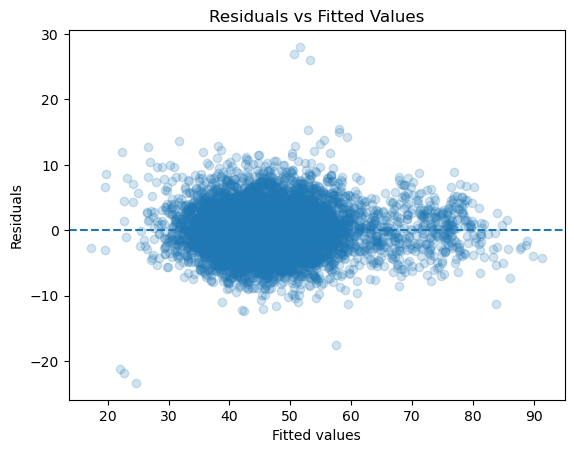

In [14]:
# Extracts fitted values and residuals
fitted_values = full_linear_model.fittedvalues
residuals = full_linear_model.resid

# Plots residuals against fitted values
plt.scatter(fitted_values, residuals, alpha=0.2) # We make alpha 0.2 to better see the density of how points are distributed

# Adds a horizontal line at zero
plt.axhline(y=0, linestyle="--")

plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted Values")

plt.show()

There is a slight skew to the left in this plot, meaning the data could violate the linearity assumption of the linear model.

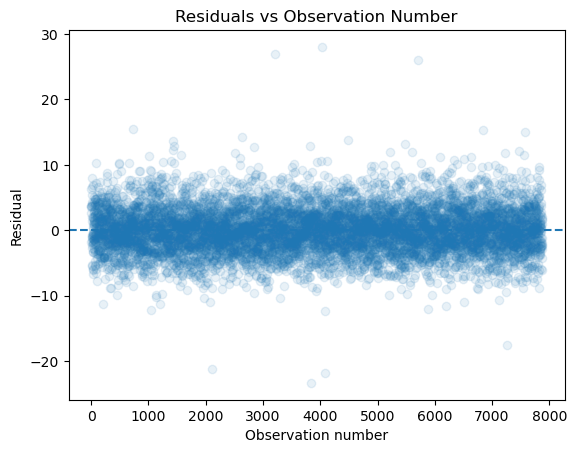

In [15]:
# Creates observation numbers: 1, 2, ..., n
observation_number = range(1, len(residuals) + 1)

plt.scatter(observation_number, residuals, alpha=0.1)

# Adds a horizontal line at zero
plt.axhline(y=0, linestyle="--")

plt.xlabel("Observation number")
plt.ylabel("Residual")
plt.title("Residuals vs Observation Number")

plt.show()

This plot suggests that the data likely doesn't violate the indepence of observations assumption.

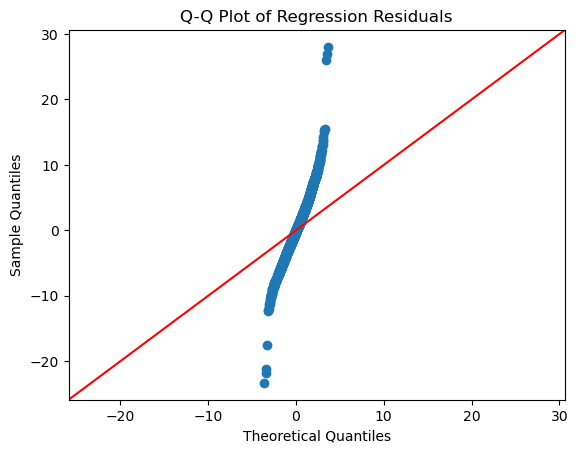

In [16]:
sm.qqplot(residuals, line="45") # Makes a Q-Q plot

plt.title("Q-Q Plot of Regression Residuals")

plt.show()

This plot suggests that there is are heavy tails, and the normality assumption of the linear model is violated.

This time, at least two of the assumptions for a linear model have been violated, linearity and normality. This means that this linear model is probably not the best way of modelling the data.

We now produce some plots of some individual columns vs attainment8_average to see if their relations are linear.

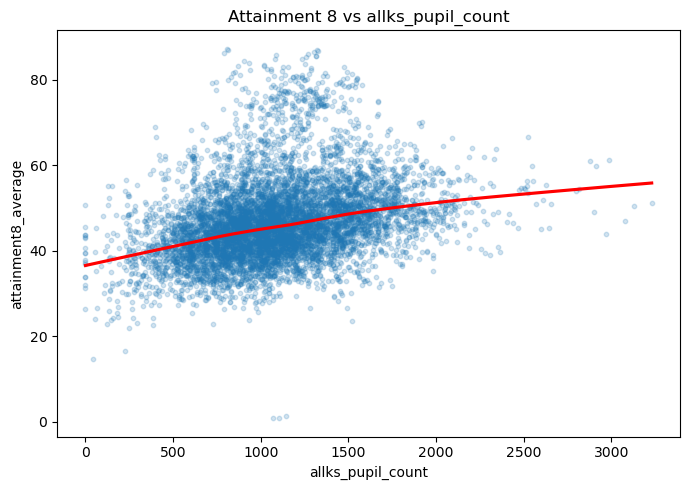

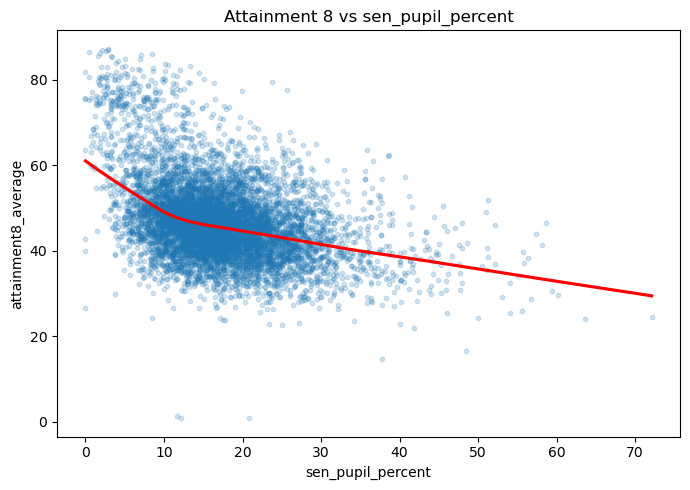

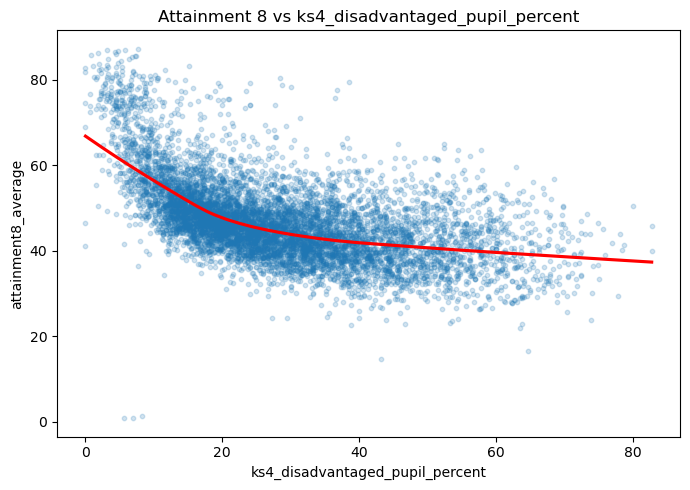

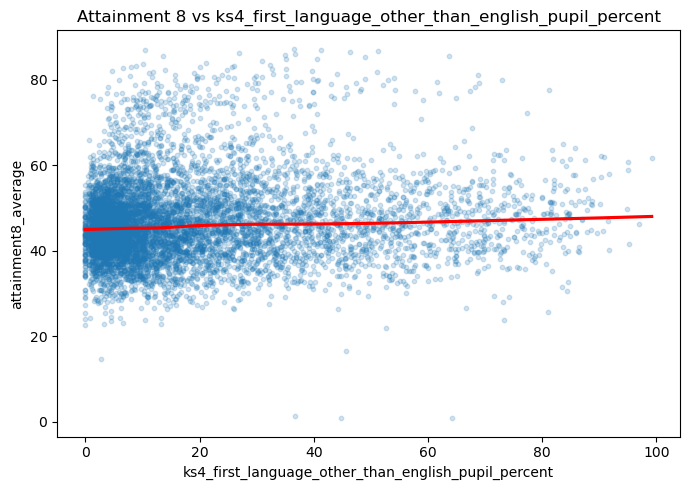

In [17]:
plot_variables = [
    'allks_pupil_count',
    'sen_pupil_percent',
    'ks4_disadvantaged_pupil_percent',
    'ks4_first_language_other_than_english_pupil_percent', 
]

plot_data = df[ # Combines the chosen predictors with the target variable
    ['attainment8_average'] + plot_variables
].copy()

for variable in plot_variables: # Plots each covariate against Attainment 8
    plt.figure(figsize=(7, 5))

    sns.regplot(
        data=plot_data,
        x=variable,
        y='attainment8_average',
        lowess=True,
        scatter_kws={'alpha': 0.2, 's': 10},
        line_kws={'color': 'red'}
    )

    plt.title(f'Attainment 8 vs {variable}')
    plt.tight_layout()
    plt.show()

Most of the relationships in these graphs do not look linear at all, so we could try transforming some of the columns and see if we can then produce a better model.

Before trying that we also produce some other potentially interesting plots which might explain the failure of a linear model.

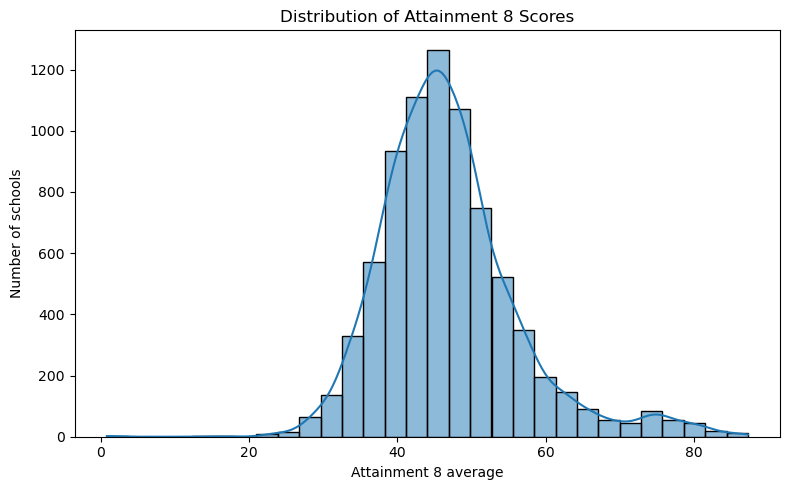

In [18]:
plt.figure(figsize=(8, 5)) # Plot the distribution of Attainment 8 scores

sns.histplot(
    data=train_data,
    x='attainment8_average',
    bins=30,
    kde=True
)

plt.xlabel('Attainment 8 average')
plt.ylabel('Number of schools')
plt.title('Distribution of Attainment 8 Scores')

plt.tight_layout()
plt.show()

So it looks as though the heavy tail on the right of the graph is likely the reasoning for the lack of normality.

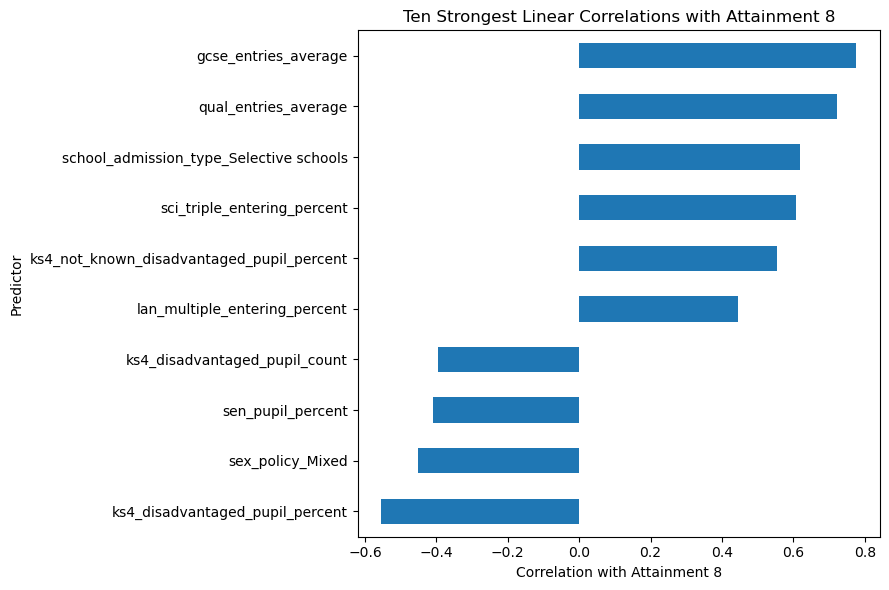

In [19]:
# Calculates correlations between numerical variables and attainment
correlations = (
    df.corr(numeric_only=True)['attainment8_average']
    .drop('attainment8_average')
)

# Select the ten predictors with the strongest absolute correlations
top_correlations = correlations.loc[
    correlations.abs().nlargest(10).index
].sort_values()

# Plot the correlations
plt.figure(figsize=(9, 6))

top_correlations.plot(kind='barh')

plt.xlabel('Correlation with Attainment 8')
plt.ylabel('Predictor')
plt.title('Ten Strongest Linear Correlations with Attainment 8')

plt.tight_layout()
plt.show()

This is interesting, students being disadvantaged shows up in 3 of the highest correlations with attainment8, schools that accept students based on gender also have a much higher correlation with attainment8. Due to the nature of attainment8, it is not overly surprising that the average number of GCSE entries would be highly correlated with it, and perhaps in a deeper analysis we would have to consider more whether or not to include this in the model, but for now we will keep it, as there could be students who would struggle with the additional workload of more GCSE's, so it's still a somewhat interesting metric to include.

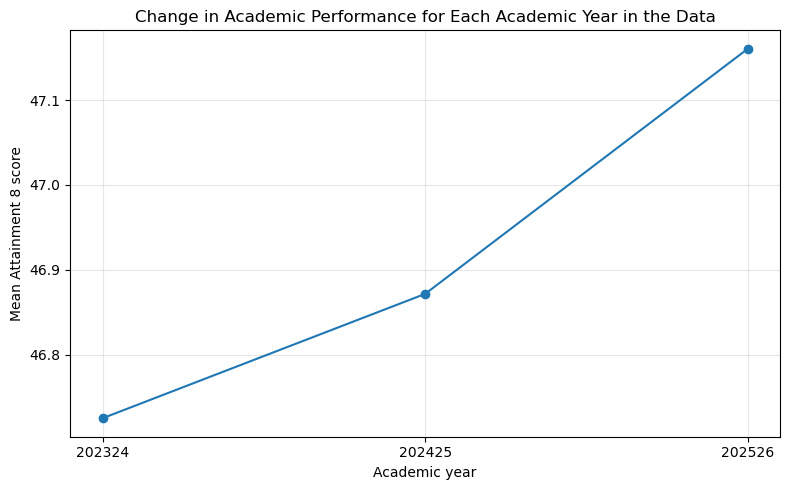

In [20]:
# Ensure time_period is stored as a numerical variable
plot_data = train_data.copy()
plot_data['time_period'] = pd.to_numeric(plot_data['time_period'])

# Calculate the mean attainment score for each academic year
yearly_attainment = (
    plot_data.groupby('time_period')['attainment8_average']
    .mean()
    .sort_index()
)

# Plot the change in average attainment over time
plt.figure(figsize=(8, 5))

plt.plot(
    yearly_attainment.index,
    yearly_attainment.values,
    marker='o'
)

plt.xlabel('Academic year')
plt.ylabel('Mean Attainment 8 score')
plt.title('Change in Academic Performance for Each Academic Year in the Data')
plt.xticks(yearly_attainment.index)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

This also shows that there is a bit of an upwards trend in attainment8 over the years

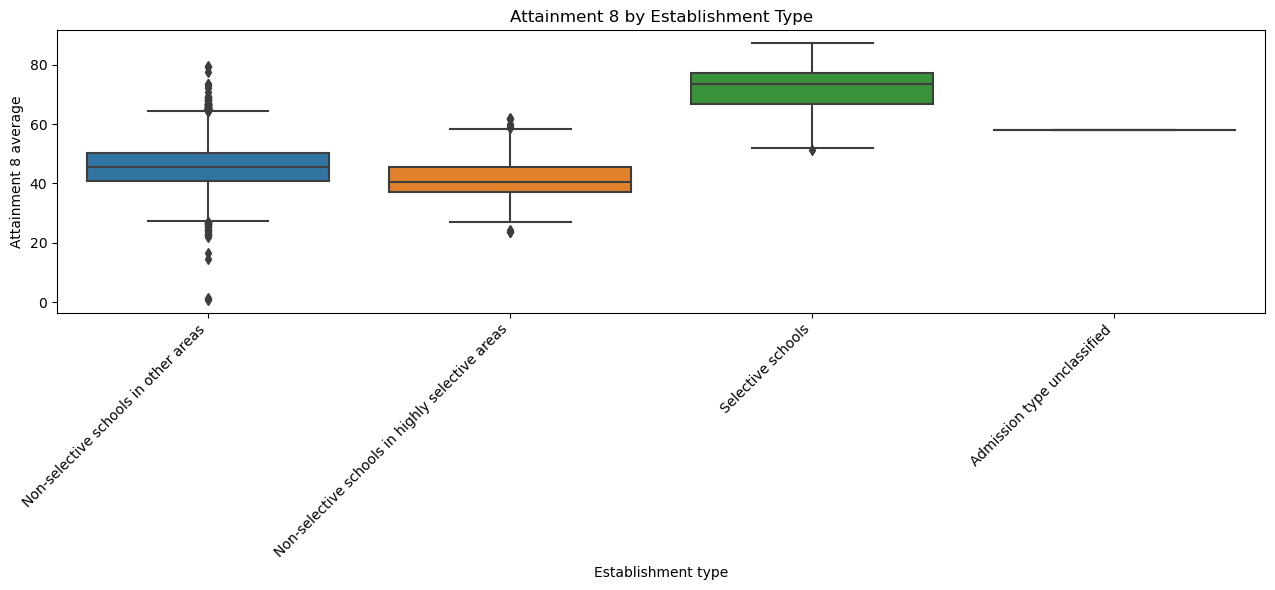

In [21]:
# Plot the distribution of attainment scores by establishment type
plt.figure(figsize=(13, 6))

sns.boxplot(
    data=train_data,
    x='school_admission_type',
    y='attainment8_average'
)

plt.xticks(rotation=45, ha='right')
plt.xlabel('Establishment type')
plt.ylabel('Attainment 8 average')
plt.title('Attainment 8 by Establishment Type')

plt.tight_layout()
plt.show()

## Transformed Model
Since we have found from the graphs that the relation between all of the predictors and the response doesn't appear to be linear, we will transform the predictors. However, due to the number of predictors available, it is not practical to go through each of them and try to decide how they should be transformed. So for each numerical variable, we will create a new column for them with a squared version of the values, a log version of the values and a reciprocal version of the values, before running the same feature selection methods, which will hopefully choose for us which of these versions is the best way of transforming the model.

We start by creating the transformed columns of the numerical variables.

In [22]:
X_transformed = X.copy() # We start by copying all of the original predictors

transformation_names = [] # This will let us check which transformations have been made

for col in X.columns:
    if X[col].nunique() <= 2: # Don't transform binary variables (which are the formerly categorical variables)
        continue
    #Quadratic transformation    
    new_name = f'{col}_squared' # Names the new column the same as before plus '_squared'
    X_transformed[new_name] = X[col] ** 2 # Creates a new column made as col^2
    transformation_names.append(new_name) # Adds to our list to keep track

    # Logarithmic transformation
    if (X[col] >= 0).all(): # Only picks variables who take exclusively non-negative values 
        new_name = f'{col}_log' # Names the new column the same as before plus '_log'
        X_transformed[new_name] = np.log1p(X[col]) # Creates a new column made as log(col)
        transformation_names.append(new_name) # Adds to our list to keep track

    # Reciprocal transformation
    if (X[col] > 0).all(): # Only picks variables who take exclusively positive values 
        new_name = f'{col}_reciprocal' # Names the new column the same as before plus '_reciprocal'
        X_transformed[new_name] = 1 / X[col] # Creates a new column made as 1/col
        transformation_names.append(new_name) # Adds to our list to keep track

print(f'Original predictors: {X.shape[1]}')
print(f'Additional transformations: {len(transformation_names)}')
print(f'Total candidate predictors: {X_transformed.shape[1]}') # This will tell us how many new variables we have made

Original predictors: 755
Additional transformations: 56
Total candidate predictors: 811


Now we try to fit a linear model including all of the available features, that is, all of the features we already had available and also all of the transformed variables we just created. After this we try to eliminate the excess transformed variables with feature selection processes.

In [23]:
# Add a constant for the intercept
X_transformed = sm.add_constant(X_transformed)

# Fit the new regression model
full_transformed_model = sm.OLS(y, X_transformed).fit()

# Display the results
print(full_transformed_model.summary())

                             OLS Regression Results                            
Dep. Variable:     attainment8_average   R-squared:                       0.881
Model:                             OLS   Adj. R-squared:                  0.869
Method:                  Least Squares   F-statistic:                     74.11
Date:                 Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                         17:54:27   Log-Likelihood:                -20445.
No. Observations:                 7873   AIC:                         4.232e+04
Df Residuals:                     7156   BIC:                         4.732e+04
Df Model:                          716                                         
Covariance Type:             nonrobust                                         
                                                                            coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------

In [24]:
# Prepare the test predictors using the same transformations as the training data
X_test_transformed = X_test.copy()

for col in X.columns:
    if X[col].nunique() <= 2:
        continue

    # Squared transformation
    X_test_transformed[f'{col}_squared'] = X_test_transformed[col] ** 2

    # Log transformation (only if all training values were non-negative)
    if (X[col] >= 0).all():
        X_test_transformed[f'{col}_log'] = np.log1p(X_test_transformed[col])

    # Reciprocal transformation (only if all training values were positive)
    if (X[col] > 0).all():
        if (X_test_transformed[col] == 0).any():
            raise ValueError(
                f"Cannot calculate reciprocal transformation for {col}: "
                "test data contains zero values."
            )
        X_test_transformed[f'{col}_reciprocal'] = (
            1 / X_test_transformed[col]
        )

# Match the training model's predictor columns and order
X_test_transformed = X_test_transformed.reindex(
    columns=X_transformed.columns,
    fill_value=0
)

# Predict attainment scores for the test data
transformed_full_predictions = full_transformed_model.predict(
    X_test_transformed
)

# Calculate test RMSE
transformed_full_rmse = np.sqrt(
    mean_squared_error(y_test, transformed_full_predictions)
)

print("Full transformed linear regression test RMSE:", transformed_full_rmse)

Full transformed linear regression test RMSE: 3.665427091669799


This is a promising start, the new model with transformed variables has the best RMSE on the test data of any of the models we have made so far, as well as the best AIC and the best adjusted R-squared values. Now we will try and improve further by carrying out feature selection. 

### Feature Selection: Principal Component Analysis
We will first try and use PCA again. In the first part PCA did not help too much but hopefully this time it can improve the model more.

In [25]:
X_transformed_predictors = X_transformed.drop( # Remove the constant column before applying PCA
    columns=['const'],
    errors='ignore'
)

pca_transformed_pipeline = Pipeline([ # Creates a pipeline that standardises the predictors and applies PCA
    ('scaler', StandardScaler()), # Standardises the predictors
    ('pca', PCA(n_components=0.999)) # We wish to retain enough components to explain 99.9% of the variance
])

X_transformed_pca = pca_transformed_pipeline.fit_transform( # Fits PCA using the transformed predictors excluding the constant
    X_transformed_predictors
)

print("Number of transformed predictors:",
      X_transformed_predictors.shape[1])

print("Number of principal components:", # Shows the number of predictors and principal components
      X_transformed_pca.shape[1])

Number of transformed predictors: 810
Number of principal components: 671


In [26]:
# Add a constant for the intercept
X_transformed_pca_const = sm.add_constant(
    X_transformed_pca,
    has_constant='add'
)

# Fit the linear regression model
pca_transformed_model = sm.OLS(
    y,
    X_transformed_pca_const
).fit()

# Display the results
print(pca_transformed_model.summary())

                             OLS Regression Results                            
Dep. Variable:     attainment8_average   R-squared:                       0.875
Model:                             OLS   Adj. R-squared:                  0.864
Method:                  Least Squares   F-statistic:                     75.32
Date:                 Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                         17:54:30   Log-Likelihood:                -20636.
No. Observations:                 7873   AIC:                         4.262e+04
Df Residuals:                     7201   BIC:                         4.730e+04
Df Model:                          671                                         
Covariance Type:             nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         46.9193      0.039   1196.66

In [27]:
# Remove the constant column from the test predictors
X_test_transformed_predictors = X_test_transformed.drop(
    columns=['const'],
    errors='ignore'
)

# Match the training predictors' column names and order
X_test_transformed_predictors = (
    X_test_transformed_predictors.reindex(
        columns=X_transformed_predictors.columns,
        fill_value=0
    )
)

# Apply the fitted scaler and PCA to the test predictors
X_test_transformed_pca = pca_transformed_pipeline.transform(
    X_test_transformed_predictors
)

# Add a constant for the regression intercept
X_test_transformed_pca_const = sm.add_constant(
    X_test_transformed_pca,
    has_constant='add'
)

In [28]:
# Predict attainment scores using the test data
pca_transformed_predictions = pca_transformed_model.predict(
    X_test_transformed_pca_const
)

# Calculate test RMSE
pca_transformed_rmse = np.sqrt(
    mean_squared_error(y_test, pca_transformed_predictions)
)

print("PCA transformed regression test RMSE:",
      pca_transformed_rmse)

PCA transformed regression test RMSE: 3.7129051706348712


So PCA has produced a model which performs worse than the full transformed model in each of the RMSE on the test data, the AIC and the adjusted R-squared. However, this still outperfoms the models without the transformed data. 

### Feature Selection: LASSO
We will now try again to select the features using the LASSO method for feature selection. In the previous part this was the best performing method so hopefully it will be again here.

In [29]:
# Create a pipeline to standardise predictors and fit LASSO
pipeline_transformed = Pipeline([
    ('scaler', StandardScaler()),  # Standardises the predictors
    ('lasso', Lasso(
        max_iter=10000,  # Sets the maximum number of iterations
        tol=1e-3,  # Sets the tolerance for convergence
        selection='cyclic'  # Updates coefficients in a fixed order
    ))
])

# Generate 20 penalty values on a logarithmic scale spanning three orders of magnitude
alpha_grid = np.logspace(
    -3,  # Lower exponent for the penalty range
    0,   # Upper exponent for the penalty range
    20   # Number of penalty values to test
)

param_grid_transformed = { # Stores the candidate penalty values for GridSearchCV
    'lasso__alpha': alpha_grid
}

cv = KFold( # Sets up the five-fold cross-validation
    n_splits=5,
    shuffle=True,
    random_state=42 
)

lasso_search_transformed = GridSearchCV( # Does a grid search to find the best penalty
    estimator=pipeline_transformed,  # Pipeline to evaluate
    param_grid=param_grid_transformed,  # Penalties to test
    scoring='neg_mean_squared_error',  # Evaluate using mean squared error
    cv=cv,  # Use the five-fold cross-validation splits
    n_jobs=-1  # Use all available CPU cores
)

lasso_search_transformed.fit(X_transformed, y) # Fits the transformed LASSO model using the data

print(
    "Best alpha:",
    lasso_search_transformed.best_params_['lasso__alpha'] # Displays the best lambda value selected by cross-validation
)

Best alpha: 0.002976351441631319


In [30]:
transformed_coefs = pd.Series( # Extracts the fitted LASSO coefficients
    lasso_search_transformed.best_estimator_.named_steps['lasso'].coef_,
    index=X_transformed.columns
)

transformed_selected = transformed_coefs[ # Select features with non-zero coefficients
    transformed_coefs.abs() > 1e-8
].index.tolist()

print("Number of selected features:", len(transformed_selected)) # Displays how many features we selected

Number of selected features: 682


So the LASSO selection has again reduced the dimensionality of the model by over 100. We can now look and see which of the new transformed variables the LASSO model decides to keep in the model.

In [31]:
lasso_transformed_model = lasso_search_transformed.best_estimator_.named_steps['lasso'] # Extracts the best fitted transformed LASSO model

coefficients = pd.Series(
    lasso_transformed_model.coef_, # Matches coefficients with their predictor names
    index=X_transformed.columns
)

selected = coefficients[coefficients.abs() > 1e-8] # Keep predictors with non-zero coefficients

selected = selected.reindex( # Arranges selected predictors with largest absolute coefficients first
    selected.abs().sort_values(ascending=False).index
)

transformed_selected = selected[ # Keep only selected covariates that are transformations
    selected.index.str.endswith(('_squared', '_log', '_reciprocal'))
]

print(transformed_selected)

qual_entries_average_log                                       2.469726
ks4_non_mobile_pupil_percent_squared                           1.546323
ks4_disadvantaged_pupil_count_squared                          1.501879
qual_entries_average_squared                                  -1.226748
allks_pupil_count_squared                                     -1.172401
gcse_entries_average_squared                                   0.935326
ks4_not_known_disadvantaged_pupil_count_squared               -0.876949
ks4_disadvantaged_pupil_count_log                             -0.852581
ks4_not_known_disadvantaged_pupil_percent_squared              0.849284
ks4_non_mobile_pupil_count_squared                             0.622226
endks4_pupil_count_log                                         0.614802
ks4_not_known_disadvantaged_pupil_count_log                    0.596755
ks4_non_mobile_pupil_percent_log                              -0.581745
ks4_first_language_other_than_english_pupil_percent_squared   -0

In [32]:
# Extract the coefficients from the best transformed LASSO model
transformed_coefs = pd.Series(
    lasso_search_transformed.best_estimator_.named_steps['lasso'].coef_,
    index=X_transformed.columns  # Matches each coefficient to its predictor
)

# Identify predictors with non-zero coefficients
transformed_selected = transformed_coefs[
    transformed_coefs.abs() > 1e-8  # Excludes coefficients basically equal to zero
].index.tolist()  # Stores the selected predictor names in a list

# Select the retained predictors and add a constant for the intercept
X_transformed_ols = sm.add_constant(
    X_transformed[transformed_selected],  # Keeps only the selected predictors
    has_constant='add'  # Ensures the intercept term is included
)

# Fit an ordinary least squares regression using the selected predictors
transformed_model = sm.OLS(
    y_lasso,  # Specify the target variable
    X_transformed_ols  # Specify the selected predictors
).fit()  # Estimate the regression coefficients

# Display the regression results
print(transformed_model.summary())

                             OLS Regression Results                            
Dep. Variable:     attainment8_average   R-squared:                       0.880
Model:                             OLS   Adj. R-squared:                  0.869
Method:                  Least Squares   F-statistic:                     78.88
Date:                 Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                         18:11:08   Log-Likelihood:                -20487.
No. Observations:                 7873   AIC:                         4.231e+04
Df Residuals:                     7203   BIC:                         4.699e+04
Df Model:                          669                                         
Covariance Type:             nonrobust                                         
                                                                           coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------

In [34]:
# Keep only the predictors selected by the transformed LASSO
X_test_transformed_selected = X_test_transformed[transformed_selected]

# Add the intercept and match the columns used to fit the model
X_test_transformed_selected = sm.add_constant(
    X_test_transformed_selected,  # Use the selected test predictors
    has_constant='add'  # Ensure the intercept is included
).reindex(
    columns=X_transformed_ols.columns,  # Match the training columns and their order
    fill_value=0  # Fill any missing columns with zero
)

# Generate predictions for the test data
transformed_test_predictions = transformed_model.predict(
    X_test_transformed_selected
)

# Calculate the test RMSE
transformed_LASSO_rmse = np.sqrt(
    mean_squared_error(y_test, transformed_test_predictions)
)

# Display the test RMSE
print("Transformed LASSO-selected linear regression test RMSE:", transformed_LASSO_rmse)

Transformed LASSO-selected linear regression test RMSE: 3.672697182352848


In [35]:
test_results = pd.DataFrame({
    'Model': [
        'Full linear regression',
        'LASSO-selected linear regression',
        'PCA regression',
        'Full transformed linear regression',
        'LASSO-selected transformed regression',
        'PCA transformed regression'
    ],
    'Test RMSE': [
        full_rmse,
        lasso_selected_rmse,
        pca_rmse,
        transformed_full_rmse,
        transformed_LASSO_rmse,
        pca_transformed_rmse
    ]
})

# Sort models from lowest to highest test RMSE
test_results = test_results.sort_values('Test RMSE')

print(test_results.to_string(index=False))

                                Model  Test RMSE
   Full transformed linear regression   3.665427
LASSO-selected transformed regression   3.672697
           PCA transformed regression   3.712905
     LASSO-selected linear regression   3.856164
                       PCA regression   3.857686
               Full linear regression   3.877675


So the LASSO-selected model with transformed variables is our best model so far based on the AIC, however, it is still outperformed by model fitted with all transformed variables base on the RMSE from our test data. So it is not immediately obvious which of the two of these we should use going forwards. But before deciding either of these are particularly useful for modeling our data, we could still repeat our linear model tests on this model to see if it actually looks as though the linear model assumptions could work after we transformed the variables.

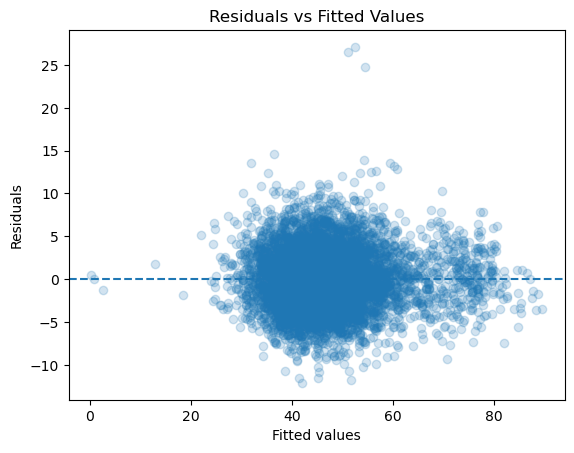

In [36]:
# Extracts fitted values and residuals
fitted_values_t = transformed_model.fittedvalues
residuals_t = transformed_model.resid

# Plots residuals against fitted values
plt.scatter(fitted_values_t, residuals_t, alpha=0.2) # We make alpha 0.2 to better see the density of how points are distributed

# Adds a horizontal line at zero
plt.axhline(y=0, linestyle="--")

plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted Values")

plt.show()

This skew to the right in this plot means the data probably violates the linearity assumption of the linear model.

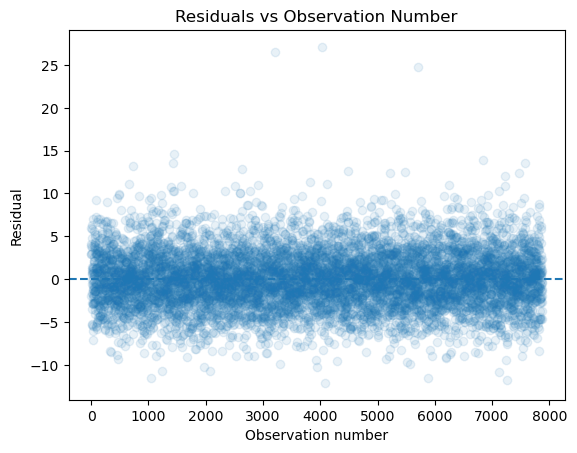

In [37]:
# Creates observation numbers: 1, 2, ..., n
observation_number_t = range(1, len(residuals_t) + 1)

plt.scatter(observation_number_t, residuals_t, alpha=0.1)

# Adds a horizontal line at zero
plt.axhline(y=0, linestyle="--")

plt.xlabel("Observation number")
plt.ylabel("Residual")
plt.title("Residuals vs Observation Number")

plt.show()

This plot suggests that the data doesn't violate the indepence of observations assumption.

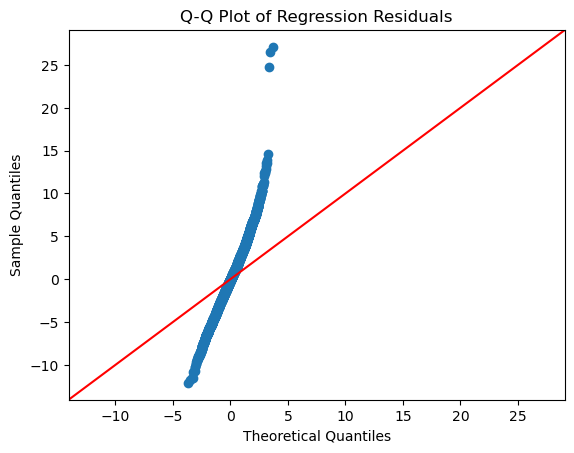

In [38]:
sm.qqplot(residuals_t, line="45") # Makes a Q-Q plot

plt.title("Q-Q Plot of Regression Residuals")

plt.show()

This plot suggests that there are still heavy tails, and the normality assumption of the linear model is violated.

This time, at least two of the assumptions for a linear model have been violated, linearity and normality. This means that this linear model with transformed variables is still probably not a good way of modelling the data. 

## Linear and Transformed Models Conclusion
In this section we have built a baseline model that we subsequently try to improve upon and we have produced code in Python that allows us to fit a linear model to our data, before trying to improve on these models with feature selection methods, and then trying to improve again by using transformations on the variables. Using these methods we were able to improve on the initial model we started with, significantly reducing the root mean squared error on the test data and the AIC. The best model we have obtained so far uses a linear model fit to the full set of transformed variables based on our test RMSE results. We also reused code we had previously found online that allowed us to analyse whether the fitted linear models were good ways of modelling the data. However, although we were able to make a large improvement over the baseline score, when examining both the initial model and the model with transformed variables, the plots suggested that using a linear model is likely not the most effective way of modelling this data specifically, due to violations of the assumptions in a linear model. To improve on the limitations of these models, we could try to identify outliers and examine whether or not they should be excluded from our models, include more types of transformations on the variables or even try to programme something that could identify which of the transformations looks as though it would best suit the relation to attainment8_average and just use that one, as opposed to adding every transformation and hoping to eliminate the irrelevant ones through feature selection.

In the next section we will move away from linear models and see if we can instead improve on our models with a random forest.

## References
- GeeksforGeeks (2025) Linear Regression in Python using Statsmodels. Available at: https://www.geeksforgeeks.org/python/linear-regression-in-python-using-statsmodels/
- Fonti, V. (2017) Feature Selection using LASSO. Research Paper in Business Analytics, Vrije Universiteit Amsterdam. Available at: https://vu-business-analytics.github.io/internship-office/papers/paper-fonti.pdf 
- Scikit-learn Developers (2026) Scikit-learn: Machine Learning in Python. Available at: https://scikit-learn.org/ 
- Statsmodels (2026) Linear regression diagnostics. Available at: https://www.statsmodels.org/stable/examples/notebooks/generated/linear_regression_diagnostics_plots.html
